# 06 – Interpretation and Energy Savings

**Project:** Energy-Aware Early Fault Detection in Semiconductor Wafer Fabrication (UCI SECOM)

This notebook explains the final model chosen in 05_Evaluation and turns its test-set results into energy and
CO₂ terms.

1. **Which sensors drive the predictions?** SHAP values and permutation importance, top 10 sensors.
2. **How much energy would early detection save?**
   E_saved = TP × E_remaining − FP × E_inspection, for detection at 30%, 50% and 70% of the process,
   with step-by-step calculations and a summary table.

All explanations use the **test set** (latest 313 wafers), the same wafers the model was evaluated on.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so `src` works from notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import math

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance

from src.config import RANDOM_STATE, MODELS_DIR, OUTPUTS_DIR
from src.data_loader import load_secom, split_xy
from src.preprocessing import time_train_test_split
from src.cost_metric import evaluate, C_FN, C_FP
from src.plotting import (apply_style, save_fig, CATEGORICAL, SEQUENTIAL_BLUES, PASS_COLOR, FAIL_COLOR,
                          REF_LINE_COLOR, TEXT_SECONDARY, TEXT_PRIMARY, SURFACE)

np.random.seed(RANDOM_STATE)
apply_style()

final = json.loads((MODELS_DIR / 'final_model.json').read_text())
model = joblib.load(ROOT / final['file'])
THRESHOLD = final['thresholds']['10:1']
print(f"Final model: {final['model']} ({final['imbalance']}), 10:1 threshold = {THRESHOLD:.3f}")

df = load_secom()
train_df, test_df = time_train_test_split(df, test_size=0.2)
X_train, y_train = split_xy(train_df)
X_test, y_test = split_xy(test_df)

# The model is a pipeline: preprocessing -> select 20 sensors -> random forest.
# Explain the forest on the 20 features it actually sees, keeping the original sensor names.
prep = model[:-1]
clf = model.named_steps['clf']
kept = np.array(model.named_steps['drop_correlated'].keep_)
FEATURES = [str(f) for f in kept[model.named_steps['select'].get_support()]]
Z_test = pd.DataFrame(prep.transform(X_test), columns=FEATURES, index=X_test.index)
Z_train = pd.DataFrame(prep.transform(X_train), columns=FEATURES, index=X_train.index)
A_test, A_train = Z_test.to_numpy(), Z_train.to_numpy()   # the forest was fitted on plain arrays

proba_test = model.predict_proba(X_test)[:, 1]
e = evaluate(y_test, proba_test, THRESHOLD, C_FN, C_FP)
print(f"Test set at the 10:1 threshold: TP {e['tp']}, FP {e['fp']}, FN {e['fn']}, TN {e['tn']}, "
      f"energy cost {e['energy_cost']:.0f} (matches 05: {final['test_10to1']['energy_cost']:.0f})")
assert e['energy_cost'] == final['test_10to1']['energy_cost']
print(f'Features used by the model ({len(FEATURES)}): {FEATURES}')

Final model: Random forest (Class weights), 10:1 threshold = 0.467


Test set at the 10:1 threshold: TP 3, FP 16, FN 14, TN 280, energy cost 156 (matches 05: 156)
Features used by the model (20): ['f000', 'f021', 'f028', 'f033', 'f059', 'f079', 'f103', 'f125', 'f129', 'f152', 'f155', 'f160', 'f197', 'f205', 'f247', 'f290', 'f333', 'f346', 'f460', 'f510']


> **About the sensor names.** SECOM sensors are anonymised: `f059` is column 59 (counting from 0) of
> `secom.data`, and the dataset does not say which tool or measurement it is. Results can therefore say
> *which* sensors matter, not what they physically measure. The values the model sees are preprocessed
> (median-imputed, Yeo-Johnson transformed, standardised), so "high" and "low" below mean relative to the
> training wafers.

## 1. SHAP values

SHAP splits each prediction into one contribution per sensor: positive values push a wafer towards **fail**,
negative values towards **pass**, and the contributions add up exactly to the predicted fail probability.
`TreeExplainer` computes them exactly for the random forest.

In [2]:
explainer = shap.TreeExplainer(clf)
sv_test = explainer.shap_values(A_test)[:, :, 1]          # class 1 = fail
sv_train = explainer.shap_values(A_train)[:, :, 1]
base = explainer.expected_value[1]

# Sanity check: base value + SHAP contributions = predicted fail probability
assert np.allclose(base + sv_test.sum(axis=1), clf.predict_proba(A_test)[:, 1], atol=1e-6)
print(f'Base value (average forest output; ~0.5 because class weights balance the classes): {base:.3f}')
print('Check passed: base + sum of SHAP values = model probability for every test wafer.')

shap_imp = pd.Series(np.abs(sv_test).mean(axis=0), index=FEATURES, name='mean_abs_shap').sort_values(ascending=False)
shap_imp_train = pd.Series(np.abs(sv_train).mean(axis=0), index=FEATURES)
rho = spearmanr(shap_imp, shap_imp_train[shap_imp.index]).statistic
print(f'Rank agreement of SHAP importance, test vs training wafers: Spearman rho = {rho:.2f}')

Base value (average forest output; ~0.5 because class weights balance the classes): 0.499
Check passed: base + sum of SHAP values = model probability for every test wafer.
Rank agreement of SHAP importance, test vs training wafers: Spearman rho = 0.83


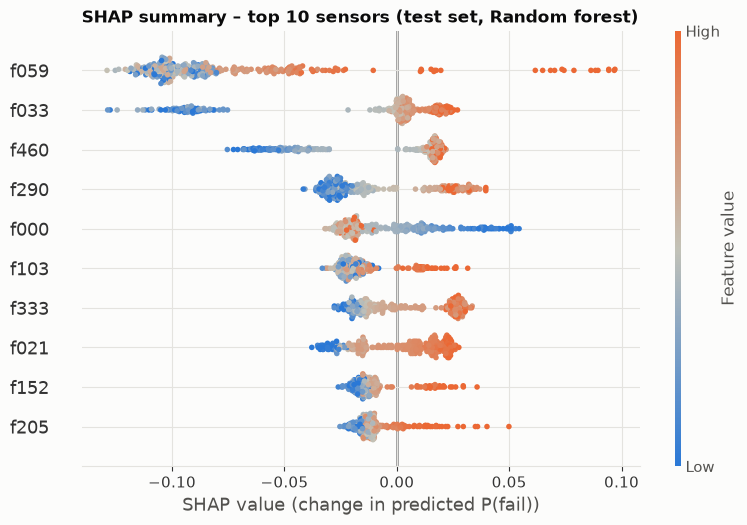

In [3]:
TOP = 10
shap_cmap = LinearSegmentedColormap.from_list('pass_fail', [PASS_COLOR, '#c3c2b7', FAIL_COLOR])
plt.figure()
shap.summary_plot(sv_test, Z_test, max_display=TOP, show=False, cmap=shap_cmap, plot_size=(8, 5.2),
                  rng=np.random.default_rng(RANDOM_STATE))
fig = plt.gcf()
ax = plt.gca()
ax.set_xlabel('SHAP value (change in predicted P(fail))')
ax.set_title(f'SHAP summary – top {TOP} sensors (test set, {final["model"]})', loc='left', fontweight='bold')
save_fig(fig, '06_shap_summary')
plt.show()

**How to read it:** each dot is one test wafer. Its position shows how much that sensor moved the wafer's
fail probability; its colour shows the sensor value (orange = high, blue = low). A sensor where orange dots
sit on the right means *high readings raise the fail risk*.

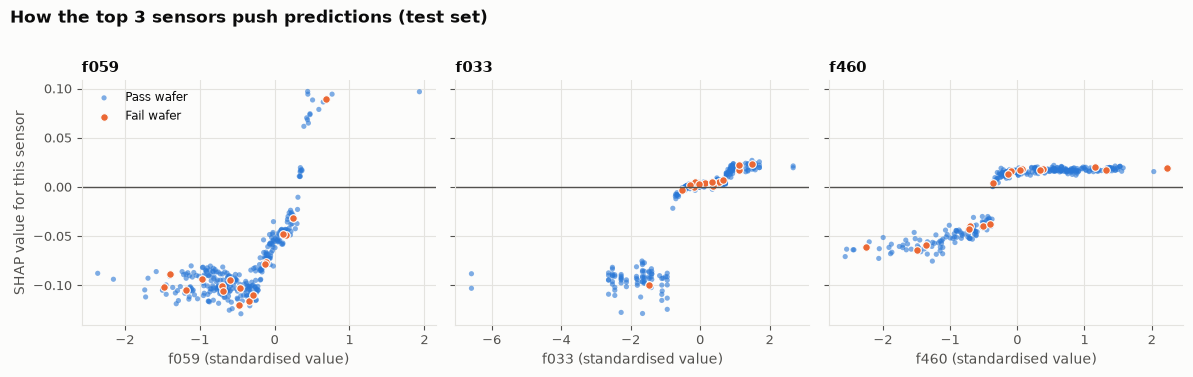

In [4]:
# Dependence plots for the 3 most important sensors: how the sensor value maps to its SHAP contribution
top3 = list(shap_imp.index[:3])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, f in zip(axes, top3):
    j = FEATURES.index(f)
    is_fail = y_test.to_numpy() == 1
    ax.scatter(Z_test[f][~is_fail], sv_test[~is_fail, j], s=14, color=PASS_COLOR, alpha=0.6, label='Pass wafer',
               edgecolor='none')
    ax.scatter(Z_test[f][is_fail], sv_test[is_fail, j], s=30, color=FAIL_COLOR, label='Fail wafer',
               edgecolor=SURFACE, linewidth=0.8)
    ax.axhline(0, color=REF_LINE_COLOR, linewidth=1)
    ax.set_xlabel(f'{f} (standardised value)')
    ax.set_title(f, fontsize=11)
axes[0].set_ylabel('SHAP value for this sensor')
axes[0].legend(loc='upper left', fontsize=8.5)
fig.suptitle('How the top 3 sensors push predictions (test set)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.97))
save_fig(fig, '06_shap_dependence_top3')
plt.show()

## 2. Permutation importance

A second, model-agnostic view: shuffle one sensor's values across the test wafers and measure how much the
model's **PR-AUC** drops. A large drop means the model relies on that sensor to rank failing wafers.
Repeated 50 times per sensor (`random_state=42`). With only 17 failing test wafers the estimates are noisy,
so the spread across repeats is shown.

In [5]:
perm = permutation_importance(clf, A_test, y_test.to_numpy(), scoring='average_precision', n_repeats=50,
                              random_state=RANDOM_STATE, n_jobs=1)
perm_imp = pd.DataFrame({'perm_mean': perm.importances_mean, 'perm_std': perm.importances_std},
                        index=FEATURES).sort_values('perm_mean', ascending=False)
base_ap = evaluate(y_test, clf.predict_proba(A_test)[:, 1], THRESHOLD)['pr_auc']
print(f'Test PR-AUC with all sensors intact: {base_ap:.3f}')
print('Drop in PR-AUC when each sensor is shuffled (mean ± SD over 50 repeats):')
print(perm_imp.round(4).head(TOP).to_string())
print(f'\nSensors whose shuffling lowers PR-AUC on average: {(perm_imp.perm_mean > 0).sum()} of {len(FEATURES)}')

Test PR-AUC with all sensors intact: 0.094
Drop in PR-AUC when each sensor is shuffled (mean ± SD over 50 repeats):
      perm_mean  perm_std
f033     0.0073    0.0193
f028     0.0066    0.0039
f103     0.0055    0.0054
f129     0.0047    0.0037
f152     0.0041    0.0043
f000     0.0039    0.0084
f510     0.0036    0.0057
f059     0.0035    0.0225
f079     0.0020    0.0028
f346    -0.0001    0.0027

Sensors whose shuffling lowers PR-AUC on average: 9 of 20


## 3. Top 10 sensors – both methods together

In [6]:
# Direction: does a HIGH sensor value push towards fail? (Spearman correlation of value vs its SHAP value)
direction = {f: spearmanr(Z_test[f], sv_test[:, FEATURES.index(f)]).statistic for f in FEATURES}

raw_missing = X_train[FEATURES].isna().mean() * 100
label_r = X_train[FEATURES].corrwith(y_train)

table = pd.DataFrame({
    'shap_rank': shap_imp.rank(ascending=False).astype(int),
    'mean_abs_shap': shap_imp,
    'perm_rank': perm_imp['perm_mean'].rank(ascending=False, method='min').astype(int),
    'perm_importance': perm_imp['perm_mean'],
    'perm_sd': perm_imp['perm_std'],
    'high_value_means': pd.Series({f: ('higher fail risk' if r > 0.2 else 'lower fail risk' if r < -0.2 else 'mixed')
                                   for f, r in direction.items()}),
    'r_with_label_raw (train)': label_r,
    'missing_%_raw (train)': raw_missing,
}).sort_values('shap_rank')
top10 = table.head(TOP)
top10.round(4).to_csv(OUTPUTS_DIR / '06_top10_sensors.csv')

pd.set_option('display.width', 200)
print(top10.round(4).to_string())
both = set(shap_imp.index[:TOP]) & set(perm_imp.index[:TOP])
print(f'\nSensors in the top 10 of BOTH methods: {len(both)} -> {sorted(both)}')
print('Saved outputs/06_top10_sensors.csv')

      shap_rank  mean_abs_shap  perm_rank  perm_importance  perm_sd  high_value_means  r_with_label_raw (train)  missing_%_raw (train)
f059          1         0.0843          8           0.0035   0.0225  higher fail risk                    0.1715                 0.5582
f033          2         0.0302          1           0.0073   0.0193  higher fail risk                    0.0866                 0.0797
f460          3         0.0280         19          -0.0120   0.0175  higher fail risk                    0.0702                 0.0797
f290          4         0.0246         20          -0.0208   0.0160  higher fail risk                   -0.0008                 0.7974
f000          5         0.0192          6           0.0039   0.0084   lower fail risk                   -0.0798                 0.4785
f103          6         0.0191          3           0.0055   0.0054  higher fail risk                    0.1281                 0.1595
f333          7         0.0190         18          -0.0

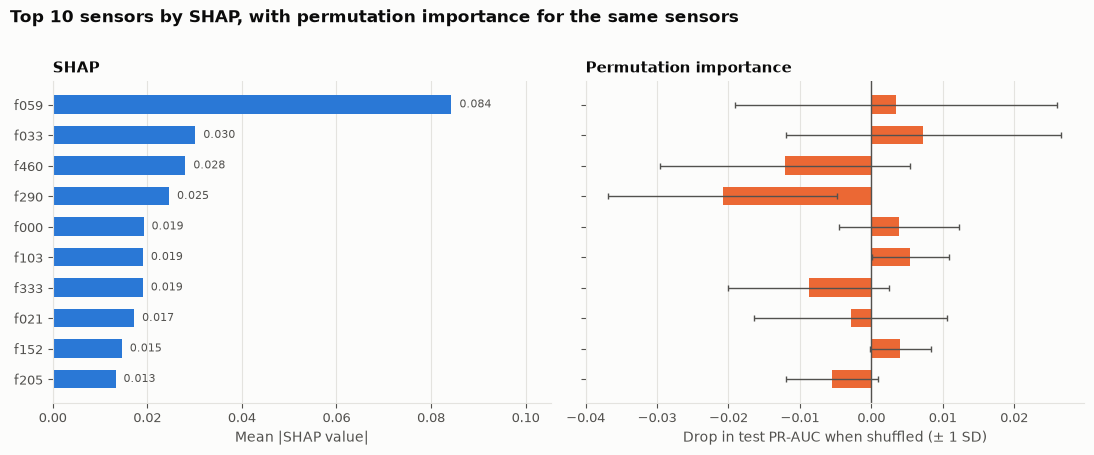

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
order = list(shap_imp.index[:TOP])[::-1]
y = np.arange(len(order))

axes[0].barh(y, shap_imp[order], color=CATEGORICAL[0], height=0.6)
axes[0].set_xlabel('Mean |SHAP value|')
axes[0].set_title('SHAP', fontsize=11)
for i, f in enumerate(order):
    axes[0].text(shap_imp[f], i, f'  {shap_imp[f]:.3f}', va='center', fontsize=8, color=TEXT_SECONDARY)
axes[0].set_xlim(0, shap_imp.max() * 1.25)

pm, ps = perm_imp.loc[order, 'perm_mean'], perm_imp.loc[order, 'perm_std']
axes[1].barh(y, pm, color=CATEGORICAL[1], height=0.6)
axes[1].errorbar(pm, y, xerr=ps, fmt='none', ecolor=REF_LINE_COLOR, elinewidth=1, capsize=2)
axes[1].axvline(0, color=REF_LINE_COLOR, linewidth=1)
axes[1].set_xlabel('Drop in test PR-AUC when shuffled (± 1 SD)')
axes[1].set_title('Permutation importance', fontsize=11)

axes[0].set_yticks(y, order)
for ax in axes:
    ax.grid(axis='y', visible=False)
fig.suptitle(f'Top {TOP} sensors by SHAP, with permutation importance for the same sensors', x=0.01, ha='left',
             fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.97))
save_fig(fig, '06_importance_comparison')
plt.show()

**Reading the importance results**

- **One sensor dominates: `f059`.** Its mean |SHAP| (0.084) is almost three times the next sensor's (`f033`,
  0.030), and high readings raise the fail risk. It is the same sensor that had the strongest correlation with
  failure in 01_EDA and the top ANOVA score in 03, so three independent views agree. But in the dependence plot,
  most test wafers with high `f059` readings actually passed: the pattern the model learned was weaker in
  October than in the training period.
- **Five sensors are in the top 10 of both methods:** `f059`, `f033`, `f103`, `f152` and `f000`. These are the
  most trustworthy candidates for an engineer to investigate first. `f000` is the only one where *high*
  values lower the fail risk.
- **Where the methods disagree, drift is the likely reason.** `f460`, `f290`, `f333` and `f205` rank high by
  SHAP (the model relies on them) but shuffling them on the test set does not hurt PR-AUC at all. The model
  learned patterns from August–September that no longer held in October. SHAP rankings on training and test
  wafers agree closely (Spearman 0.83), so the model's internal logic is stable; it is the data that changed.
- **Permutation importance is noisy here:** only 9 of 20 sensors lower PR-AUC when shuffled, and the spread
  across repeats is often larger than the mean (e.g. `f059` 0.004 ± 0.023), because the test set has only
  17 failing wafers.
- **Energy-aware angle:** the model needs only 20 of the 590 sensors (3%), and most of its signal comes from a
  handful of them, so monitoring could focus on a small set of sensors.
- The sensors are anonymised, so we can say *which* columns matter but not which tool or measurement they are.

## 4. Energy savings from early fault detection

### Model of the saving

If the model flags a wafer partway through the process, a **true fault (TP)** can be scrapped immediately,
so the energy of all the remaining process steps is not spent on it. A **false alarm (FP)** sends a good wafer
for one extra inspection, which costs some energy, after which it continues normally. Missed faults (FN) and
correctly passed wafers (TN) are processed exactly as without screening, so they do not change the balance.

**E_saved = TP × E_remaining − FP × E_inspection**

### Inputs and assumptions

| Quantity | Value | Source |
|---|---|---|
| Wafer size | 200 mm diameter | given |
| Fab energy intensity | 1.432 kWh per cm² of wafer | Hu & Chuah (2003) |
| Grid emission factor | 0.740 kg CO₂e per kWh | Energy Commission (Suruhanjaya Tenaga) Malaysia |
| Detection point | 30%, 50%, 70% of the process | scenarios |
| E_remaining | (1 − detection point) × energy per wafer | assumes energy is spread evenly over the process |
| **E_inspection** | **1% of the energy per wafer** | **our assumption – see below** |
| TP, FP | from the final model on the test set (10 : 1 threshold) | 05_Evaluation |

**E_inspection is an assumption.** No figure was given for the energy of one extra inspection. A wafer passes
through several hundred process steps, so a single metrology/inspection step is very likely *below* 1% of the
whole-process energy; using 1% is deliberately conservative (it makes false alarms look more expensive).
Section 4.4 shows how the result changes with this value and the break-even point where screening stops
saving energy.

**Other simplifications:** energy is assumed to be spent evenly across the process; the model's sensor
readings are assumed to be available at the detection point; and a flagged fault is assumed to be scrapped
rather than reworked.

In [8]:
# ---- Inputs ----
WAFER_DIAMETER_MM = 200
ENERGY_PER_CM2_KWH = 1.432          # Hu & Chuah (2003)
GRID_KG_CO2E_PER_KWH = 0.740        # Energy Commission Malaysia
INSPECTION_FRACTION = 0.01          # ASSUMPTION: one extra inspection = 1% of a wafer's fab energy
STAGES = [0.30, 0.50, 0.70]         # detection at 30%, 50%, 70% of the process

TP, FP, FN, TN = e['tp'], e['fp'], e['fn'], e['tn']
N_TEST = len(y_test)

### 4.1 Step-by-step calculation

In [9]:
r_cm = WAFER_DIAMETER_MM / 10 / 2
area = math.pi * r_cm ** 2
E_wafer = ENERGY_PER_CM2_KWH * area
E_insp = INSPECTION_FRACTION * E_wafer

print('Step 1 - Wafer area')
print(f'  radius = {WAFER_DIAMETER_MM} mm / 2 = {r_cm:.0f} cm')
print(f'  area   = pi x r^2 = pi x {r_cm:.0f}^2 = {area:.2f} cm^2\n')

print('Step 2 - Fabrication energy for one wafer')
print(f'  E_wafer = {ENERGY_PER_CM2_KWH} kWh/cm^2 x {area:.2f} cm^2 = {E_wafer:.1f} kWh\n')

print('Step 3 - Energy of one extra inspection (assumption)')
print(f'  E_inspection = {INSPECTION_FRACTION:.0%} x {E_wafer:.1f} kWh = {E_insp:.2f} kWh\n')

print('Step 4 - Model results on the test set (10:1 threshold)')
print(f'  {N_TEST} wafers: TP = {TP} faults caught, FP = {FP} false alarms, FN = {FN} faults missed\n')

print('Step 5 - Saving at each detection point')
for s in STAGES:
    E_rem = (1 - s) * E_wafer
    gross = TP * E_rem
    insp = FP * E_insp
    net = gross - insp
    print(f'  Detection at {s:.0%} of the process')
    print(f'    E_remaining = (1 - {s:.2f}) x {E_wafer:.1f} = {E_rem:.1f} kWh per wafer')
    print(f'    TP x E_remaining  = {TP} x {E_rem:.1f} = {gross:,.1f} kWh')
    print(f'    FP x E_inspection = {FP} x {E_insp:.2f} = {insp:,.1f} kWh')
    print(f'    E_saved = {gross:,.1f} - {insp:,.1f} = {net:,.1f} kWh')
    print(f'    CO2e avoided = {net:,.1f} kWh x {GRID_KG_CO2E_PER_KWH} kg/kWh = {net * GRID_KG_CO2E_PER_KWH:,.1f} kg\n')

Step 1 - Wafer area
  radius = 200 mm / 2 = 10 cm
  area   = pi x r^2 = pi x 10^2 = 314.16 cm^2

Step 2 - Fabrication energy for one wafer
  E_wafer = 1.432 kWh/cm^2 x 314.16 cm^2 = 449.9 kWh

Step 3 - Energy of one extra inspection (assumption)
  E_inspection = 1% x 449.9 kWh = 4.50 kWh

Step 4 - Model results on the test set (10:1 threshold)
  313 wafers: TP = 3 faults caught, FP = 16 false alarms, FN = 14 faults missed

Step 5 - Saving at each detection point
  Detection at 30% of the process
    E_remaining = (1 - 0.30) x 449.9 = 314.9 kWh per wafer
    TP x E_remaining  = 3 x 314.9 = 944.7 kWh
    FP x E_inspection = 16 x 4.50 = 72.0 kWh
    E_saved = 944.7 - 72.0 = 872.8 kWh
    CO2e avoided = 872.8 kWh x 0.74 kg/kWh = 645.8 kg

  Detection at 50% of the process
    E_remaining = (1 - 0.50) x 449.9 = 224.9 kWh per wafer
    TP x E_remaining  = 3 x 224.9 = 674.8 kWh
    FP x E_inspection = 16 x 4.50 = 72.0 kWh
    E_saved = 674.8 - 72.0 = 602.8 kWh
    CO2e avoided = 602.8 kWh x 0

### 4.2 Summary table

In [10]:
def savings(tp, fp, stages=STAGES, e_insp=E_insp):
    rows = []
    for s in stages:
        E_rem = (1 - s) * E_wafer
        net = tp * E_rem - fp * e_insp
        rows.append({'detection_point': f'{s:.0%}', 'E_remaining_kWh_per_wafer': E_rem, 'TP': tp, 'FP': fp,
                     'saved_on_faults_kWh': tp * E_rem, 'spent_on_inspections_kWh': fp * e_insp,
                     'E_saved_kWh': net, 'CO2e_avoided_kg': net * GRID_KG_CO2E_PER_KWH,
                     'E_saved_kWh_per_1000_wafers': net / N_TEST * 1000,
                     'CO2e_t_per_1000_wafers': net * GRID_KG_CO2E_PER_KWH / N_TEST * 1000 / 1000})
    return pd.DataFrame(rows)

summary = savings(TP, FP)
summary.round(2).to_csv(OUTPUTS_DIR / '06_energy_savings.csv', index=False)
print(f'{final["model"]} on the {N_TEST} test wafers (10:1 threshold), E_inspection = {E_insp:.2f} kWh')
print(summary.round(1).to_string(index=False))
print('\nSaved outputs/06_energy_savings.csv')

Random forest on the 313 test wafers (10:1 threshold), E_inspection = 4.50 kWh
detection_point  E_remaining_kWh_per_wafer  TP  FP  saved_on_faults_kWh  spent_on_inspections_kWh  E_saved_kWh  CO2e_avoided_kg  E_saved_kWh_per_1000_wafers  CO2e_t_per_1000_wafers
            30%                      314.9   3  16                944.7                      72.0        872.8            645.8                       2788.4                     2.1
            50%                      224.9   3  16                674.8                      72.0        602.8            446.1                       1926.0                     1.4
            70%                      135.0   3  16                404.9                      72.0        332.9            246.4                       1063.6                     0.8

Saved outputs/06_energy_savings.csv


### 4.3 Context: how much of the possible saving does the model capture?

- **Perfect detector:** catches all 17 faults with no false alarms – the maximum possible saving.
- **The final model at its three thresholds from 05** (tuned for 5 : 1, 10 : 1 and 20 : 1 cost ratios).

The 10 : 1 cost ratio used to pick the threshold was a modelling assumption. In energy terms the actual ratio
is E_remaining ÷ E_inspection, which is far larger (computed below), so a lower threshold that catches more
faults could save more energy even though it raises more false alarms.

In [11]:
print('Energy-implied cost ratio (missed fault : false alarm) = E_remaining / E_inspection')
for s in STAGES:
    print(f'  detection at {s:.0%}: {(1 - s) * E_wafer:.1f} / {E_insp:.2f} = {(1 - s) / INSPECTION_FRACTION:.0f} : 1')

ctx = []
n_fail = int(y_test.sum())
for label, tp, fp in [('Perfect detector', n_fail, 0)] + [
        (f"{final['model']} @ {r} threshold",
         evaluate(y_test, proba_test, t)['tp'], evaluate(y_test, proba_test, t)['fp'])
        for r, t in final['thresholds'].items()]:
    s = savings(tp, fp)
    ctx.append({'policy': label, 'TP': tp, 'FP': fp,
                **{f'E_saved @ {d} (kWh)': v for d, v in zip(s['detection_point'], s['E_saved_kWh'])}})
ctx = pd.DataFrame(ctx).set_index('policy')
for d in ['30%', '50%', '70%']:
    ctx[f'share of perfect @ {d}'] = ctx[f'E_saved @ {d} (kWh)'] / ctx.loc['Perfect detector', f'E_saved @ {d} (kWh)']
print()
print(ctx.round(2).to_string())
ctx.round(2).to_csv(OUTPUTS_DIR / '06_energy_context.csv')

Energy-implied cost ratio (missed fault : false alarm) = E_remaining / E_inspection
  detection at 30%: 314.9 / 4.50 = 70 : 1
  detection at 50%: 224.9 / 4.50 = 50 : 1
  detection at 70%: 135.0 / 4.50 = 30 : 1


                                TP  FP  E_saved @ 30% (kWh)  E_saved @ 50% (kWh)  E_saved @ 70% (kWh)  share of perfect @ 30%  share of perfect @ 50%  share of perfect @ 70%
policy                                                                                                                                                                       
Perfect detector                17   0              5353.53              3823.95              2294.37                    1.00                    1.00                    1.00
Random forest @ 5:1 threshold    0   0                 0.00                 0.00                 0.00                    0.00                    0.00                    0.00
Random forest @ 10:1 threshold   3  16               872.76               602.83               332.91                    0.16                    0.16                    0.15
Random forest @ 20:1 threshold   4  59               994.23               634.33               274.42                    0.19     

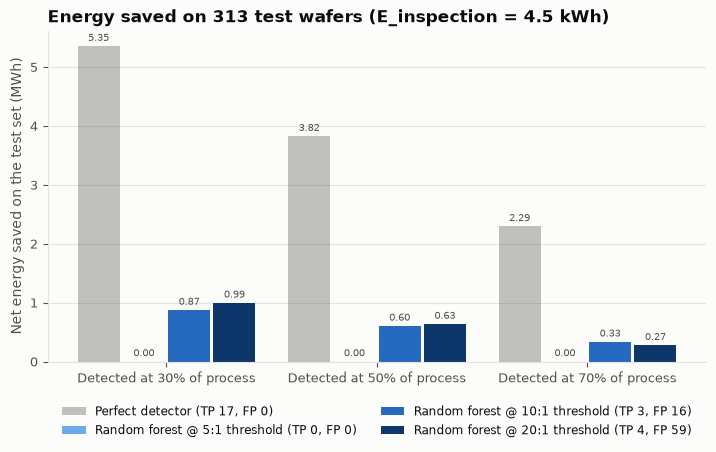

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.3))
policies = list(ctx.index)
colors = [REF_LINE_COLOR] + [SEQUENTIAL_BLUES[2], SEQUENTIAL_BLUES[4], SEQUENTIAL_BLUES[6]]
x = np.arange(len(STAGES)); w = 0.2
for j, (p, c) in enumerate(zip(policies, colors)):
    vals = [ctx.loc[p, f'E_saved @ {s:.0%} (kWh)'] / 1000 for s in STAGES]
    pos = x + (j - 1.5) * (w + 0.015)
    ax.bar(pos, vals, width=w, color=c, label=f"{p} (TP {ctx.loc[p, 'TP']}, FP {ctx.loc[p, 'FP']})", zorder=2,
           alpha=0.35 if p == 'Perfect detector' else 1)
    for pp, v in zip(pos, vals):
        ax.text(pp, v + 0.05, f'{v:.2f}', ha='center', va='bottom', fontsize=7.5, color=TEXT_SECONDARY)
ax.set_xticks(x, [f'Detected at {s:.0%} of process' for s in STAGES])
ax.set_ylabel('Net energy saved on the test set (MWh)')
ax.set_title(f'Energy saved on {N_TEST} test wafers (E_inspection = {E_insp:.1f} kWh)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8.5)
ax.grid(axis='x', visible=False)
save_fig(fig, '06_energy_savings')
plt.show()

### 4.4 Sensitivity to the inspection-energy assumption

In [13]:
print('Break-even E_inspection (screening saves energy only if E_inspection is below this):')
print('  E_inspection* = TP x E_remaining / FP')
for s in STAGES:
    be = TP * (1 - s) * E_wafer / FP if FP else float('inf')
    print(f'  detection at {s:.0%}: {TP} x {(1 - s) * E_wafer:.1f} / {FP} = {be:.1f} kWh '
          f'({be / E_wafer:.1%} of a wafer\'s fab energy)')

sens = []
for frac in [0.005, 0.01, 0.02, 0.05, 0.10]:
    s = savings(TP, FP, e_insp=frac * E_wafer)
    sens.append({'E_inspection (% of wafer energy)': f'{frac:.1%}', 'E_inspection (kWh)': frac * E_wafer,
                 **{f'E_saved @ {d} (kWh)': v for d, v in zip(s['detection_point'], s['E_saved_kWh'])},
                 **{f'CO2e @ {d} (kg)': v for d, v in zip(s['detection_point'], s['CO2e_avoided_kg'])}})
sens = pd.DataFrame(sens)
print()
print(sens.round(1).to_string(index=False))
sens.round(2).to_csv(OUTPUTS_DIR / '06_energy_sensitivity.csv', index=False)
print('\nSaved outputs/06_energy_context.csv and outputs/06_energy_sensitivity.csv')

Break-even E_inspection (screening saves energy only if E_inspection is below this):
  E_inspection* = TP x E_remaining / FP
  detection at 30%: 3 x 314.9 / 16 = 59.0 kWh (13.1% of a wafer's fab energy)
  detection at 50%: 3 x 224.9 / 16 = 42.2 kWh (9.4% of a wafer's fab energy)
  detection at 70%: 3 x 135.0 / 16 = 25.3 kWh (5.6% of a wafer's fab energy)

E_inspection (% of wafer energy)  E_inspection (kWh)  E_saved @ 30% (kWh)  E_saved @ 50% (kWh)  E_saved @ 70% (kWh)  CO2e @ 30% (kg)  CO2e @ 50% (kg)  CO2e @ 70% (kg)
                            0.5%                 2.2                908.7                638.8                368.9            672.5            472.7            273.0
                            1.0%                 4.5                872.8                602.8                332.9            645.8            446.1            246.4
                            2.0%                 9.0                800.8                530.9                260.9            592.6         

**Reading the energy results**

- **Net saving on the 313 test wafers** (about two weeks of production in this dataset), with
  E_inspection = 4.5 kWh: **873 kWh at 30%**, **603 kWh at 50%** and **333 kWh at 70%** of the process,
  i.e. **646, 446 and 246 kg CO₂e**. Scaled to 1000 wafers: 2.8, 1.9 and 1.1 MWh (2.1, 1.4 and 0.8 t CO₂e).
- **Earlier detection saves much more:** each caught fault avoids 315 kWh at 30% but only 135 kWh at 70%.
- **The saving comes from the 3 caught faults.** The 16 false alarms cost only 72 kWh in total. The model
  captures 15–16% of what a perfect detector would save (5.4, 3.8 and 2.3 MWh); the 14 missed faults are the
  lost opportunity.
- **The 10 : 1 cost ratio undervalues a caught fault in energy terms.** The energy-implied ratio is
  E_remaining ÷ E_inspection = 70 : 1, 50 : 1 and 30 : 1 at the three detection points. The 20 : 1 threshold
  catches one more fault (4) at the price of 59 false alarms and saves more at 30% (994 vs 873 kWh) and 50%
  (634 vs 603 kWh), but less at 70% (274 vs 333 kWh). If the cost metric is meant to represent energy, the
  threshold should be tuned with a ratio close to E_remaining ÷ E_inspection.
- **The result holds unless inspection is expensive.** Screening saves energy at every detection point as long
  as one inspection uses less than 25 kWh (5.6% of a wafer's fabrication energy); the break-even values are
  59, 42 and 25 kWh at 30%, 50% and 70%. Only at 10% does the saving turn negative at 50% and 70%.

**Caveats for the report**

- 1.432 kWh/cm² is a whole-fab average (including facility systems such as clean-room air handling) from
  Taiwanese fabs around 2003, applied linearly to one 200 mm wafer; it is an order-of-magnitude figure, not a
  measured value for this production line.
- Energy is assumed to be spread evenly over the process, sensor data is assumed to be available at the
  detection point, and flagged faults are assumed to be scrapped, not reworked.
- With only 17 failing test wafers, one fault more or less changes the saving by 135–315 kWh, so the
  per-1000-wafer figures are rough estimates.

### References

- Hu, S.-C., & Chuah, Y. K. (2003). Power consumption of semiconductor fabs in Taiwan. *Energy, 28*(8),
  895–907.
- Energy Commission (Suruhanjaya Tenaga) Malaysia – grid electricity emission factor, 0.740 kg CO₂e/kWh.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS 30*.
- McCann, M., & Johnston, A. (2008). SECOM [Dataset]. UCI Machine Learning Repository.